# 04charts: final charts for the four findings

**What it does.** Makes the case study charts for the four chosen findings, in the project's theme (pine green headings, KTX blue, SRT orange, metro aqua), and saves them as PNG images for the case study page and PDF.

1. SRT grew the market: KTX and SRT at the ten busiest shared stations, 2019, against KTX in 2016.
2. New lines created travel: the Gangneung corridor, and the Honam stations against all other KTX stations.
3. An uneven recovery: high-speed rail against its pre-COVID path; metro rail lines against 2019.
4. Reliability: service disruptions per million train km.

**Inputs:** the clean tables in `data/clean` and `data/names_en.csv`.
**Outputs:** `docs/images/cs_f1_srt.png`, `cs_f2_newlines.png`, `cs_f3_recovery.png`, `cs_f3_metro.png`, `cs_f4_reliability.png`.

**Data credit:** Korea Railroad Corporation (KORAIL), via data.go.kr, railstat.korail.com and info.korail.com.

## 0. Settings

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from statsmodels.tsa.holtwinters import ExponentialSmoothing

CLEAN = Path("data/clean")  # <- clean tables
NAMES = Path("data/names_en.csv")  # <- English names
OUT = Path("docs/images")  # <- case study images

SRT_YEAR_BEFORE = 2016  # <- last year before SRT
SRT_YEAR_AFTER = 2019  # <- last full year before COVID
N_STATIONS = 10  # <- stations shown in chart 1
TRAIN_START = "2017-01"  # <- forecast training start
TRAIN_END = "2019-12"  # <- forecast training end
METRO_BASE = 2019  # <- metro base year
METRO_NOW = 2025  # <- metro latest year

C_HEAD = "#1f5c45"  # <- VISUAL: theme heading colour (pine green)
C_KTX = "#2a78d6"  # <- VISUAL: KTX blue
C_SRT = "#eb6834"  # <- VISUAL: SRT orange
C_METRO = "#1baf7a"  # <- VISUAL: metro aqua
C_GREY = "#a3a29c"  # <- VISUAL: neutral marks
C_INK = "#1d2433"  # <- VISUAL: titles
C_TEXT = "#52514e"  # <- VISUAL: labels
C_GRID = "#e5e4e0"  # <- VISUAL: grid lines
WIDTH_IN = 8.0  # <- VISUAL: chart width in inches
DPI = 200  # <- VISUAL: image resolution (8 in x 200 = 1600 px wide)
FONTS = ["Archivo", "Malgun Gothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]  # <- VISUAL: first installed font is used; Hangul falls back to the next

OUT.mkdir(parents=True, exist_ok=True)
installed = {f.name for f in font_manager.fontManager.ttflist}
FONTS = [f for f in FONTS if f in installed]
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"font.family": FONTS, "font.size": 10, "text.color": C_TEXT, "axes.labelcolor": C_TEXT, "xtick.color": C_TEXT, "ytick.color": C_TEXT, "axes.edgecolor": C_GRID, "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": C_INK, "axes.titlepad": 12, "legend.frameon": False, "savefig.facecolor": "white"})

names = pd.read_csv(NAMES)
EN = dict(zip(names["ko"], names["en"]))
LABEL = {ko: f"{ko} ({en})" for ko, en in EN.items()}
print("chart fonts:", FONTS)

chart fonts: ['Malgun Gothic', 'DejaVu Sans']


In [2]:
def title(fig, text):
    fig.suptitle(text, x=0.01, y=0.99, ha="left", va="top", fontsize=12, fontweight="bold", color=C_INK)


def finish(fig, name, source, top=0.95):
    fig.tight_layout(rect=(0, 0.04, 1, top))
    fig.text(0.01, 0.005, "Source: " + source, fontsize=8, color=C_TEXT, ha="left", va="bottom")
    fig.savefig(OUT / name, dpi=DPI, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    print("saved", name)


SRC_STATIONS = "KORAIL, Korean Railway Statistics (railstat.korail.com), boardings and alightings by station."
SRC_MONTHLY = "KORAIL, Korean Railway Statistics; riders by train type, monthly. Path: Holt-Winters model fitted to 2017 to 2019."
SRC_METRO = "KORAIL metro rail statistics (info.korail.com), boardings by station, all months."
SRC_EVENTS = "KORAIL, Korean Railway Statistics; accidents and service disruptions, and scheduled train km."

In [3]:
stations = pd.read_csv(CLEAN / "station_year_ktx_srt.csv")
stations["station"] = stations["station"].replace({"여수엑수포": "여수엑스포"})
st = stations.groupby(["operator", "station", "year"])[["board", "alight"]].sum().sum(axis=1).unstack("year")
ktx_st = st.loc["KTX"]
srt_st = st.loc["SRT"]
riders_m = pd.read_csv(CLEAN / "riders_month.csv", parse_dates=["month"], index_col="month")
line_year = pd.read_csv(CLEAN / "line_year.csv")
ktx_month = pd.read_csv(CLEAN / "ktx_station_month.csv", parse_dates=["month"])
runs = pd.read_csv(CLEAN / "runs_year.csv")
events = pd.read_csv(CLEAN / "disruptions_month.csv", parse_dates=["month"])
metro_st = pd.read_csv(CLEAN / "metro_station_month.csv")
print("loaded")

loaded


## 1. SRT grew the market

For each of the ten busiest stations shared by KTX and SRT in 2019: a bar of KTX (blue) and SRT (orange) riders in 2019, and a dark tick at KTX's own level in 2016. Where the blue part ends left of the tick, KTX lost riders; where the whole bar ends right of it, the market grew.

14 shared stations: KTX -3%, KTX plus SRT +36%


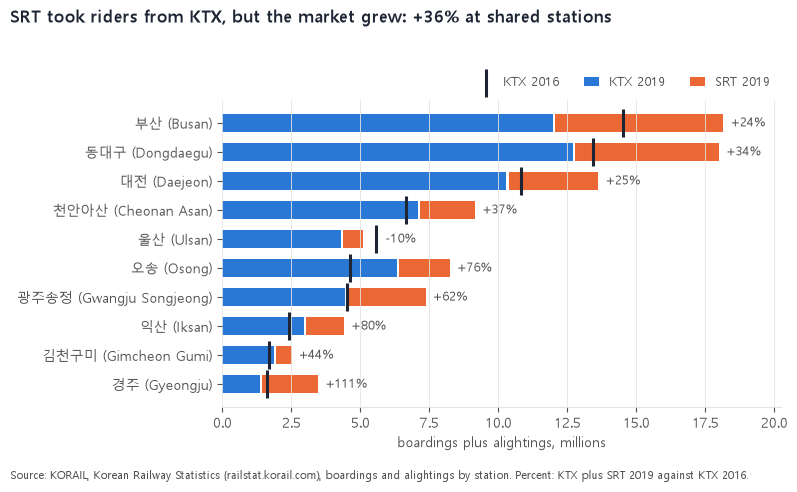

saved cs_f1_srt.png


In [4]:
served = [s for s in srt_st.index[srt_st[SRT_YEAR_AFTER] > 0] if s in ktx_st.index and ktx_st.loc[s, SRT_YEAR_BEFORE] > 0]
f1 = pd.DataFrame(index=served)
f1["ktx_before"] = ktx_st.loc[served, SRT_YEAR_BEFORE] / 1e6
f1["ktx_after"] = ktx_st.loc[served, SRT_YEAR_AFTER] / 1e6
f1["srt_after"] = srt_st.loc[served, SRT_YEAR_AFTER] / 1e6
total = f1.sum()
growth_all = (total["ktx_after"] + total["srt_after"]) / total["ktx_before"] * 100 - 100
ktx_all = total["ktx_after"] / total["ktx_before"] * 100 - 100
print(f"{len(f1)} shared stations: KTX {ktx_all:+.0f}%, KTX plus SRT {growth_all:+.0f}%")

top = f1.sort_values("ktx_before", ascending=False).head(N_STATIONS).iloc[::-1]
top.index = top.index.map(LABEL)
fig, ax = plt.subplots(figsize=(WIDTH_IN, 4.8))
y = np.arange(len(top))
ax.barh(y, top["ktx_after"], height=0.62, color=C_KTX, label=f"KTX {SRT_YEAR_AFTER}")
ax.barh(y, top["srt_after"], left=top["ktx_after"] + 0.08, height=0.62, color=C_SRT, label=f"SRT {SRT_YEAR_AFTER}")
ax.scatter(top["ktx_before"], y, marker="|", s=420, linewidths=2.2, color=C_INK, zorder=4, label=f"KTX {SRT_YEAR_BEFORE}")
for yi, (_, r) in zip(y, top.iterrows()):
    both = r["ktx_after"] + r["srt_after"]
    change = both / r["ktx_before"] * 100 - 100
    ax.text(max(both, r["ktx_before"]) + 0.35, yi, f"{change:+.0f}%", va="center", fontsize=9, color=C_TEXT)
ax.set_yticks(y, top.index)
ax.set_xlabel("boardings plus alightings, millions")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, (top["ktx_after"] + top["srt_after"]).max() * 1.12)
ax.legend(loc="lower right", ncols=3, fontsize=9, bbox_to_anchor=(1, 1.0), handlelength=1.2)
title(fig, f"SRT took riders from KTX, but the market grew: {growth_all:+.0f}% at shared stations")
finish(fig, "cs_f1_srt.png", SRC_STATIONS + " Percent: KTX plus SRT 2019 against KTX 2016.", top=0.96)

## 2. New lines created travel

Left: riders on the Gangneung line (KTX, opened December 2017) and on the old Yeongdong and Taebaek lines it could have drawn from. Right: KTX boardings plus alightings in the 12 months after the Honam high-speed line opened (2 April 2015) against the 12 months before, at the eight Honam stations and at all other KTX stations open in both periods.

Honam +46.8% | other 32 stations +3.4%
Gangneung 2019: 2.57 | old lines 2016 -> 2019: 1.19 -> 1.01


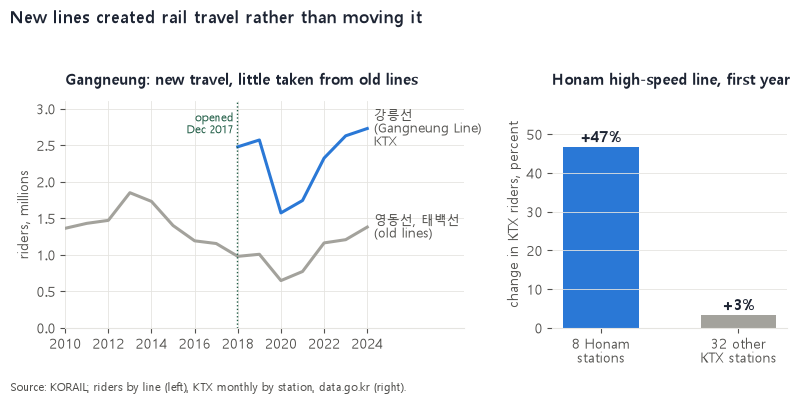

saved cs_f2_newlines.png


In [5]:
corr = line_year[line_year["line"].isin(["강릉선", "영동선", "태백선"]) & (line_year["type"] != "total")]
corr = corr.groupby(["line", "year"])["riders"].sum().unstack("line").fillna(0) / 1e6
corr["old"] = corr["영동선"] + corr["태백선"]
corr.loc[corr.index < 2018, "강릉선"] = np.nan
corr = corr.loc[2010:]

honam = ["광주", "광주송정", "목포", "나주", "정읍", "익산", "김제", "장성"]
wide = ktx_month.pivot_table(index="month", columns="station", values="riders_k")
hb = wide.loc["2014-04":"2015-03", honam].sum().sum()
ha = wide.loc["2015-04":"2016-03", honam].sum().sum()
rest = wide.drop(columns=honam)
rest = rest.loc[:, (rest.loc["2014-04":"2016-03"] > 0).all()]
rb = rest.loc["2014-04":"2015-03"].sum().sum()
ra = rest.loc["2015-04":"2016-03"].sum().sum()
honam_pct = ha / hb * 100 - 100
rest_pct = ra / rb * 100 - 100
print(f"Honam {honam_pct:+.1f}% | other {rest.shape[1]} stations {rest_pct:+.1f}%")
print("Gangneung 2019:", round(corr.loc[2019, "강릉선"], 2), "| old lines 2016 -> 2019:", round(corr.loc[2016, "old"], 2), "->", round(corr.loc[2019, "old"], 2))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(WIDTH_IN, 3.9), gridspec_kw={"width_ratios": [1.7, 1]})
a1.plot(corr.index, corr["강릉선"], color=C_KTX, linewidth=2.2)
a1.plot(corr.index, corr["old"], color=C_GREY, linewidth=2.2)
a1.text(2024.3, corr.loc[2024, "강릉선"], "강릉선\n(Gangneung Line)\nKTX", va="center", fontsize=9, color=C_TEXT)
a1.text(2024.3, corr.loc[2024, "old"], "영동선, 태백선\n(old lines)", va="center", fontsize=9, color=C_TEXT)
a1.axvline(2017.97, color=C_HEAD, linewidth=1, linestyle=":")
a1.text(2017.8, 2.95, "opened\nDec 2017", ha="right", va="top", fontsize=8, color=C_HEAD)
a1.set_xlim(2010, 2028.5)
a1.set_xticks(range(2010, 2025, 2))
a1.set_ylim(0, 3.1)
a1.set_ylabel("riders, millions")
a1.set_title("Gangneung: new travel, little taken from old lines", fontsize=10.5)

bars = a2.bar(["8 Honam\nstations", f"{rest.shape[1]} other\nKTX stations"], [honam_pct, rest_pct], color=[C_KTX, C_GREY], width=0.55)
for b, v in zip(bars, [honam_pct, rest_pct]):
    a2.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:+.0f}%", ha="center", fontsize=11, fontweight="bold", color=C_INK)
a2.set_ylim(0, max(honam_pct, rest_pct) * 1.25)
a2.set_ylabel("change in KTX riders, percent")
a2.grid(axis="x", visible=False)
a2.set_title("Honam high-speed line, first year", fontsize=10.5)
title(fig, "New lines created rail travel rather than moving it")
finish(fig, "cs_f2_newlines.png", "KORAIL; riders by line (left), KTX monthly by station, data.go.kr (right).")

## 3. An uneven recovery

**High-speed rail.** Monthly KTX plus SRT boardings against the path it was on before COVID. The path is shown as a band between two versions of the same model (a straight trend and a levelling-off trend), because three years of training data cannot pin down one line.

**Metro rail.** Change in boardings by line, 2019 to 2025, for lines open in both years.

KTX plus SRT: 94.9 m (2019) -> 110.4 m (2023): +16%


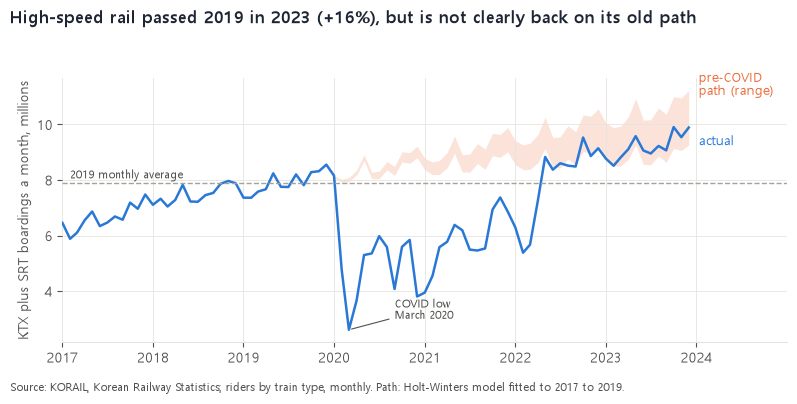

saved cs_f3_recovery.png


In [6]:
hs = ((riders_m["KTX"] + riders_m["SRT"]) / 1e6).asfreq("MS")
train = hs[TRAIN_START:TRAIN_END]
fc_a = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit().forecast(48)
fc_b = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12).fit().forecast(48)
lo = np.minimum(fc_a, fc_b)
hi = np.maximum(fc_a, fc_b)
y2019 = hs["2019"].sum()
y2023 = hs["2023"].sum()
print("KTX plus SRT:", round(y2019, 1), "m (2019) ->", round(y2023, 1), "m (2023):", f"{y2023 / y2019 * 100 - 100:+.0f}%")

fig, ax = plt.subplots(figsize=(WIDTH_IN, 3.9))
ax.fill_between(lo.index, lo, hi, color=C_SRT, alpha=0.18, linewidth=0)
ax.plot(hs["2017":].index, hs["2017":], color=C_KTX, linewidth=1.8)
ax.axhline(hs["2019"].mean(), color=C_GREY, linewidth=1, linestyle="--")
ax.text(pd.Timestamp("2017-02-01"), hs["2019"].mean() + 0.15, "2019 monthly average", fontsize=8, color=C_TEXT)
ax.text(pd.Timestamp("2024-01-10"), hi.iloc[-1] + 0.2, "pre-COVID\npath (range)", va="center", fontsize=9, color=C_SRT)
ax.text(pd.Timestamp("2024-01-10"), hs.iloc[-1] - 0.5, "actual", va="center", fontsize=9, color=C_KTX)
ax.annotate("COVID low\nMarch 2020", xy=(hs.idxmin(), hs.min()), xytext=(pd.Timestamp("2020-09-01"), 3.0), fontsize=8, color=C_TEXT, arrowprops={"arrowstyle": "-", "color": C_TEXT, "linewidth": 0.8})
ax.set_xlim(pd.Timestamp("2017-01-01"), pd.Timestamp("2024-12-31"))
ax.set_ylabel("KTX plus SRT boardings a month, millions")
title(fig, f"High-speed rail passed 2019 in 2023 ({y2023 / y2019 * 100 - 100:+.0f}%), but is not clearly back on its old path")
finish(fig, "cs_f3_recovery.png", SRC_MONTHLY)

metro rail network -3.9%


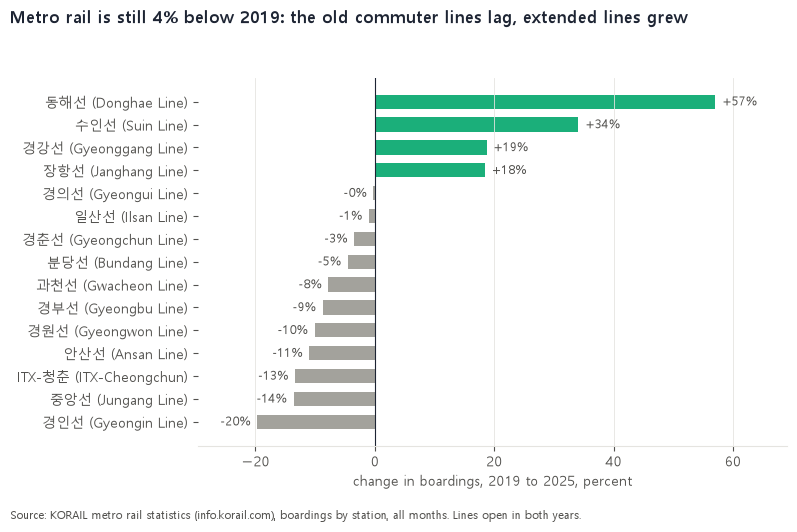

saved cs_f3_metro.png


In [7]:
ml = metro_st.groupby(["line", "year"])["board"].sum().unstack("year") / 1e6
ml = ml[ml[METRO_BASE].notna() & ml[METRO_NOW].notna()]
ml["pct"] = ml[METRO_NOW] / ml[METRO_BASE] * 100 - 100
ml = ml.sort_values("pct")
net = metro_st.groupby("year")["board"].sum()
net_pct = net[METRO_NOW] / net[METRO_BASE] * 100 - 100
print(f"metro rail network {net_pct:+.1f}%")

fig, ax = plt.subplots(figsize=(WIDTH_IN, 5.2))
labels = [LABEL.get(l, l) for l in ml.index]
colors = [C_METRO if v >= 0 else C_GREY for v in ml["pct"]]
ax.barh(labels, ml["pct"], color=colors, height=0.62)
ax.axvline(0, color=C_INK, linewidth=0.8)
for i, v in enumerate(ml["pct"]):
    ax.text(v + (1.2 if v >= 0 else -1.2), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=C_TEXT)
ax.set_xlim(ml["pct"].min() - 10, ml["pct"].max() + 12)
ax.set_xlabel(f"change in boardings, {METRO_BASE} to {METRO_NOW}, percent")
ax.grid(axis="y", visible=False)
title(fig, f"Metro rail is still {abs(net_pct):.0f}% below 2019: the old commuter lines lag, extended lines grew")
finish(fig, "cs_f3_metro.png", SRC_METRO + " Lines open in both years.")

## 4. Reliability

Service disruptions per million train km (KORAIL all trains plus SR passenger trains; train km per day x 365, unit inferred). The labels give the number of disruptions in each year.

{2016: 1.34, 2017: 1.21, 2018: 0.82, 2019: 1.9, 2020: 0.91, 2021: 0.58, 2022: 0.49, 2023: 0.46, 2024: 0.45}
2022 to 2024 against 2016 to 2019: -65%


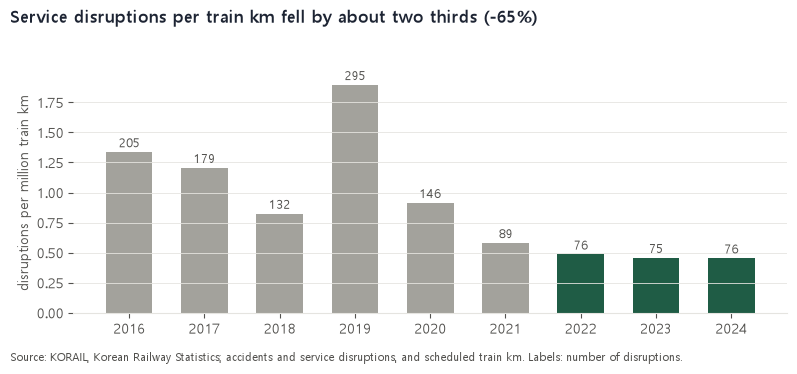

saved cs_f4_reliability.png


In [8]:
ev = events.groupby(events["month"].dt.year)["disruptions"].sum()
km = runs[(((runs["operator"] == "KORAIL") & (runs["group"] == "합계")) | ((runs["operator"] == "SR") & (runs["group"] == "여객"))) & (runs["train_type"] == "소계")]
km = km.groupby("year")["train_km_per_day"].sum() * 365 / 1e6
rate = ev / km
drop = rate.loc[2022:2024].mean() / rate.loc[2016:2019].mean() * 100 - 100
print(rate.round(2).to_dict())
print(f"2022 to 2024 against 2016 to 2019: {drop:+.0f}%")

fig, ax = plt.subplots(figsize=(WIDTH_IN, 3.6))
colors = [C_HEAD if y >= 2022 else C_GREY for y in rate.index]
ax.bar(rate.index, rate, color=colors, width=0.62)
for x, v, n in zip(rate.index, rate, ev):
    ax.text(x, v + 0.04, f"{n}", ha="center", fontsize=9, color=C_TEXT)
ax.set_xticks(rate.index)
ax.set_ylabel("disruptions per million train km")
ax.grid(axis="x", visible=False)
title(fig, f"Service disruptions per train km fell by about two thirds ({drop:+.0f}%)")
finish(fig, "cs_f4_reliability.png", SRC_EVENTS + " Labels: number of disruptions.")

___
**END**